# Análisis de errores y set de estrés

Etapa de análisis de errores del pipeline. Corre en local (CPU alcanza) con los `best.pt` ya bajados a `runs/`.

1. **Predicciones en test** de cada detector, a confianza baja, guardadas para no recalcular.
2. **Métricas al punto de operación** (τ): P, R y falsos positivos por imagen negativa (`evaluacion.py`).
3. **Peores casos por clase:** los falsos positivos de mayor confianza y los falsos negativos de objetos más grandes. Se exporta una plantilla para **clasificarlos por causa a mano** y se resume. De acá salen las figuras cualitativas.
4. **H1 con el modelo:** recall por tamaño de caja (small / medium / large, COCO) a 640 vs. 960.
5. **H2:** falsos positivos por imagen negativa y recall, con negativas (R1) vs. sin negativas (R5), a varios τ.
6. **Set de estrés:** falsos positivos por imagen en ~150 negativas externas a D-Fire, por categoría, con y sin clasificador de recortes. Es la medida honesta de generalización (el test oficial tiene casi-duplicados de train; ver `eda.ipynb`).

In [1]:
from pathlib import Path

import cv2
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from tqdm.auto import tqdm
from ultralytics import YOLO

import evaluacion
import recortes

REPO_ROOT = Path.cwd()
SPLIT_ROOT = REPO_ROOT / "data" / "data"
RUNS_DIR, RESULTS_DIR, FIG_DIR = REPO_ROOT / "runs", REPO_ROOT / "results", REPO_ROOT / "figures"
ESTRES_DIR = REPO_ROOT / "data" / "estres"
CACHE_DIR = RESULTS_DIR / "errores"
for d in (RESULTS_DIR, FIG_DIR, CACHE_DIR):
    d.mkdir(parents=True, exist_ok=True)
DEVICE = 0 if torch.cuda.is_available() else "cpu"
CLASES = tuple(evaluacion.CLASS_NAMES.values())
COLORES = {"fire": (230, 40, 40), "smoke": (60, 180, 230)}  # RGB (las imágenes se muestran en RGB)

## 1. Configuración

- `RUN`: el detector del sistema (el mejor según `master.csv`).
- `RUNS_H1`: los dos runs que comparan resolución (R1 a 640 y R4 a 960, mismo tamaño de modelo).
- `RUNS_H2`: con negativas (R1) vs. sin negativas (R5).
- `TAU`: punto de operación. Las predicciones se guardan desde `CONF_MIN`, así que cambiar τ no obliga a recalcular.

In [2]:
RUN = "yolo11n_640_neg_s42"
RUNS_H1 = {"yolo11n_640_neg_s42": 640, "yolo11n_960_neg_s42": 960}
RUNS_H2 = {"yolo11n_640_neg_s42": "con negativas (R1)", "yolo11n_640_noneg_s42": "sin negativas (R5)"}
IMGSZ = {RUN: 640, **RUNS_H1, **{r: 640 for r in RUNS_H2}}
CLF_WEIGHTS = RUNS_DIR / "clasificador" / "weights" / "best.pt"
CLF_IMGSZ = 224
TAU = 0.40
UMBRAL_CLF = 0.50
CONF_MIN = 0.05
CLF_CONF_MIN = 0.25
N_PEORES = 20
SEED = 42
SMOKE_TEST = False  # True: 150 imágenes de test y pesos de COCO si faltan los runs

def pesos(run: str):
    p = RUNS_DIR / run / "weights" / "best.pt"
    if p.exists():
        return p
    if SMOKE_TEST:
        return "yolo11n.pt"
    raise FileNotFoundError(f"No está {p}")

clasificador = YOLO(CLF_WEIGHTS) if CLF_WEIGHTS.exists() else (YOLO("yolo11n-cls.pt") if SMOKE_TEST else None)
if SMOKE_TEST and not CLF_WEIGHTS.exists():
    recortes.CLASE_REAL = "tench"  # ImageNet no tiene "real": solo para ejercitar el camino
print("Clasificador:", CLF_WEIGHTS if CLF_WEIGHTS.exists() else ("ImageNet (SMOKE_TEST)" if clasificador else "no disponible"))

Clasificador: c:\Proyectos\CV2\detección_incendios\runs\clasificador\weights\best.pt


## 2. Predicciones en test

Una vez por detector: predicciones con `conf ≥ CONF_MIN` (y `p_real` para las que superan `CLF_CONF_MIN`, si hay clasificador) en `results/errores/test_preds_<run>.csv`, y el ground truth en `test_gts.csv`.

In [3]:
test_imgs = sorted((SPLIT_ROOT / "test" / "images").iterdir())
if SMOKE_TEST:
    test_imgs = sorted(np.random.default_rng(SEED).choice(test_imgs, 150, replace=False))
RUTA = {p.stem: p for p in test_imgs}

def p_real(img: np.ndarray, cajas: list) -> list[float]:
    if clasificador is None or not cajas:
        return [np.nan] * len(cajas)
    idx = recortes.indice_clase_real(clasificador.names)
    res = clasificador.predict([recortes.recortar(img, *b) for b in cajas], imgsz=CLF_IMGSZ, device=DEVICE, verbose=False)
    return [float(r.probs.data[idx]) for r in res]

def predecir(run: str, rutas: list[Path], cache: Path, con_gt: bool) -> tuple[pd.DataFrame, pd.DataFrame | None]:
    gts_path = CACHE_DIR / "test_gts.csv"
    if cache.exists() and not SMOKE_TEST and (not con_gt or gts_path.exists()):
        return pd.read_csv(cache), (pd.read_csv(gts_path) if con_gt else None)
    det = YOLO(pesos(run))
    preds, gts = [], []
    for p in tqdm(rutas, desc=f"{run} en {cache.stem}"):
        r = det.predict(str(p), imgsz=IMGSZ.get(run, 640), conf=CONF_MIN, device=DEVICE, verbose=False)[0]
        H, W = r.orig_shape
        if con_gt:
            gts += [{"imagen": p.stem, **g} for g in evaluacion.leer_gt(SPLIT_ROOT / "test" / "labels" / f"{p.stem}.txt", W, H)]
        xyxy, confs = r.boxes.xyxy.tolist(), r.boxes.conf.tolist()
        pr = [np.nan] * len(xyxy)
        sobre = [i for i, c in enumerate(confs) if c > CLF_CONF_MIN]
        for i, v in zip(sobre, p_real(r.orig_img, [xyxy[i] for i in sobre])):
            pr[i] = v
        for (x1, y1, x2, y2), conf, cls, v in zip(xyxy, confs, r.boxes.cls.tolist(), pr):
            preds.append({"imagen": p.stem, "clase": r.names[int(cls)], "conf": conf,
                          "x1": x1, "y1": y1, "x2": x2, "y2": y2, "ancho_img": W, "alto_img": H, "p_real": v})
    preds = pd.DataFrame(preds, columns=["imagen", "clase", "conf", "x1", "y1", "x2", "y2", "ancho_img", "alto_img", "p_real"])
    preds.to_csv(cache, index=False)
    if con_gt:
        gts = pd.DataFrame(gts, columns=["imagen", "clase", "x1", "y1", "x2", "y2", "ancho_img", "alto_img"])
        gts.to_csv(gts_path, index=False)
    return preds, (gts if con_gt else None)

preds, gts = predecir(RUN, test_imgs, CACHE_DIR / f"test_preds_{RUN}.csv", con_gt=True)
negativas = sorted(set(RUTA) - set(gts["imagen"]))
print(f"{len(RUTA)} imágenes ({len(negativas)} negativas) | {len(preds)} predicciones | {len(gts)} cajas GT")

4306 imágenes (2005 negativas) | 12666 predicciones | 5193 cajas GT


## 3. Métricas al punto de operación

In [4]:
filas = {"detector": evaluacion.evaluar(preds, gts, negativas, TAU)}
if clasificador is not None:
    filas["detector + clasificador"] = evaluacion.evaluar(preds, gts, negativas, TAU, UMBRAL_CLF)
pd.DataFrame(filas).round(3)

,detector,detector + clasificador
tau,0.400,0.400
umbral_clf,NaN,0.500
TP_smoke,1661.000,1558.000
FP_smoke,302.000,274.000
FN_smoke,654.000,757.000
P_smoke,0.846,0.850
R_smoke,0.717,0.673
TP_fire,1593.000,1567.000
FP_fire,452.000,429.000
FN_fire,1285.000,1311.000


## 4. Peores casos por clase

Al τ operativo (sin clasificador, para ver los errores del detector):

- **Falsos positivos de mayor confianza.** Se marca si caen en una imagen negativa y si son una **confusión de clase** (la caja coincide con GT de la otra clase: humo detectado como fuego o al revés).
- **Falsos negativos de objetos más grandes** (los chicos se pierden por H1; los grandes que se pierden son los que hay que explicar).

Caja verde = ground truth; roja / celeste = predicción de fuego / humo.

In [5]:
p_emp, g_emp = evaluacion.emparejar(evaluacion.filtrar(preds, TAU), gts)

# Confusión de clase: FP que coincide (IoU ≥ 0,5) con GT de la otra clase
p_emp["confusion_clase"] = False
for idx, r in p_emp[~p_emp["tp"]].iterrows():
    otra = gts[(gts["imagen"] == r["imagen"]) & (gts["clase"] != r["clase"])]
    if len(otra):
        p_emp.at[idx, "confusion_clase"] = evaluacion.iou(r[evaluacion.COLS].to_numpy(float)[None], otra[evaluacion.COLS].to_numpy(float)).max() >= 0.5
p_emp["en_negativa"] = p_emp["imagen"].isin(negativas)
g_emp["area"] = (g_emp["x2"] - g_emp["x1"]) * (g_emp["y2"] - g_emp["y1"])

peores = []
for clase in CLASES:
    fp = p_emp[(p_emp["clase"] == clase) & ~p_emp["tp"]].nlargest(N_PEORES, "conf")
    fn = g_emp[(g_emp["clase"] == clase) & ~g_emp["detectada"]].nlargest(N_PEORES, "area")
    peores += [fp.assign(tipo="FP"), fn.assign(tipo="FN")]
peores = pd.concat(peores, ignore_index=True)
print(peores.groupby(["tipo", "clase"]).size().rename("casos").to_frame())
print("FP en imágenes negativas:", int(peores.loc[peores["tipo"] == "FP", "en_negativa"].sum()),
      "| confusiones de clase:", int(peores.loc[peores["tipo"] == "FP", "confusion_clase"].sum()))

            casos
tipo clase       
FN   fire      20
     smoke     20
FP   fire      20
     smoke     20
FP en imágenes negativas: 0 | confusiones de clase: 5


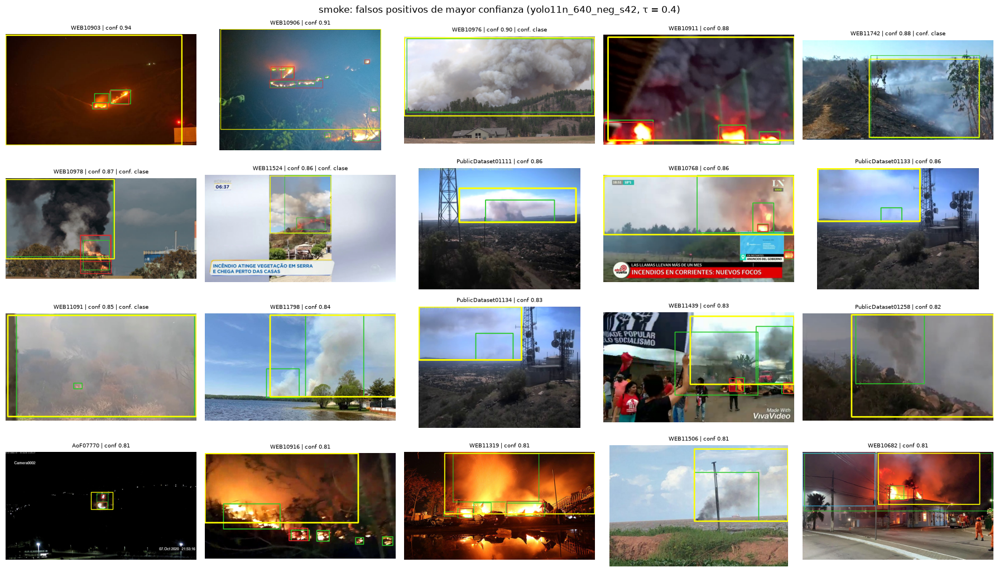

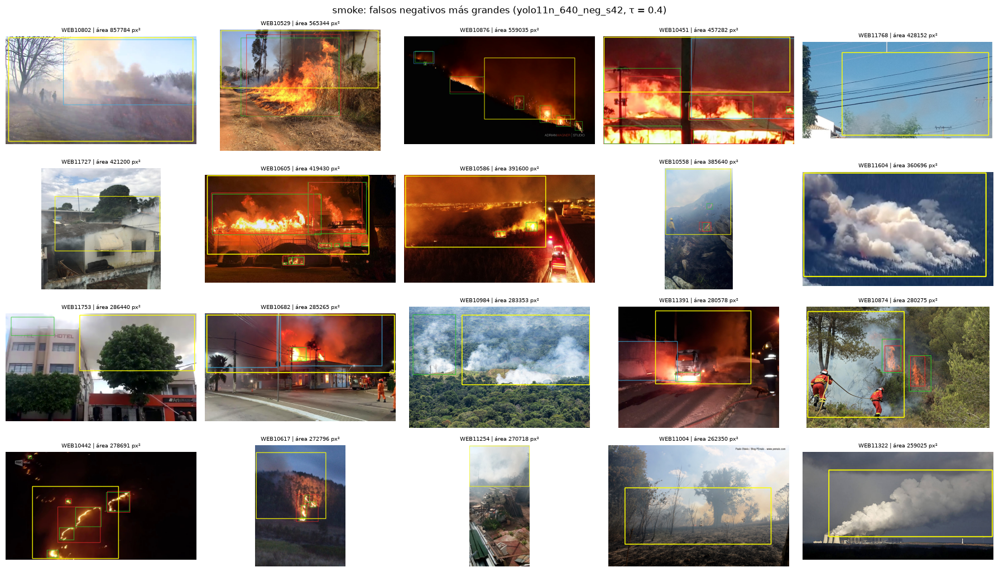

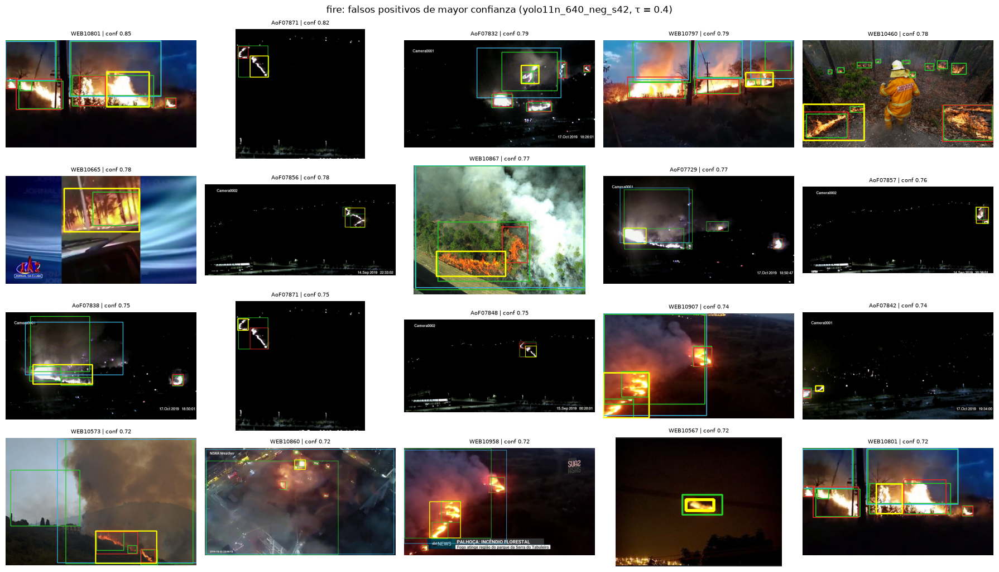

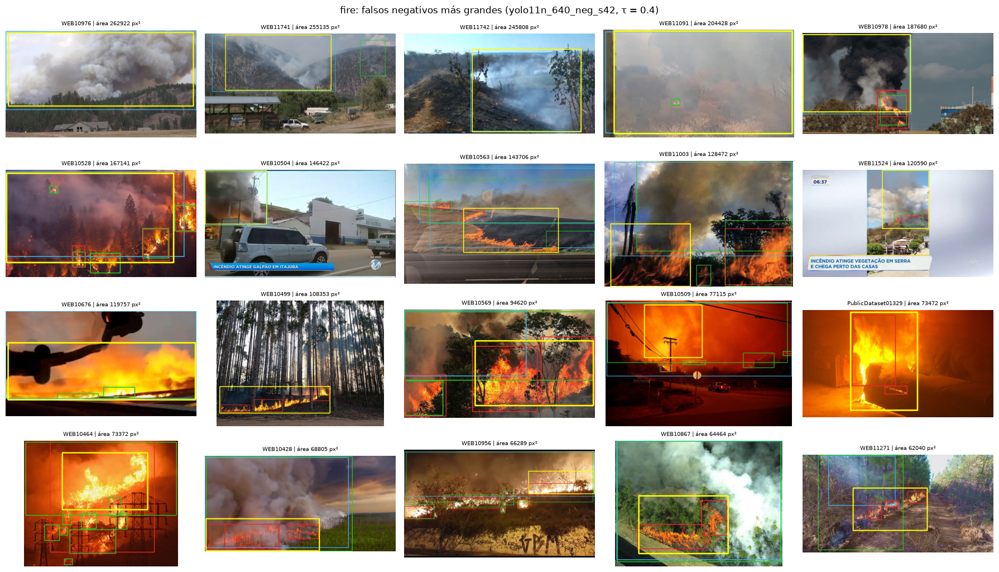

In [6]:
def mostrar(casos: pd.DataFrame, titulo: str, archivo: str, columnas: int = 5):
    if casos.empty:
        print(f"{titulo}: sin casos")
        return
    filas = int(np.ceil(len(casos) / columnas))
    fig, axes = plt.subplots(filas, columnas, figsize=(3.6 * columnas, 2.6 * filas), squeeze=False)
    for ax, (_, c) in zip(axes.flat, casos.iterrows()):
        img = cv2.cvtColor(cv2.imread(str(RUTA[c["imagen"]])), cv2.COLOR_BGR2RGB)
        for g in gts[gts["imagen"] == c["imagen"]].itertuples():
            cv2.rectangle(img, (int(g.x1), int(g.y1)), (int(g.x2), int(g.y2)), (40, 200, 40), 2)
        for p in preds[(preds["imagen"] == c["imagen"]) & (preds["conf"] > TAU)].itertuples():
            cv2.rectangle(img, (int(p.x1), int(p.y1)), (int(p.x2), int(p.y2)), COLORES.get(p.clase, (255, 255, 255)), 2)
        x1, y1, x2, y2 = (int(c[k]) for k in evaluacion.COLS)
        cv2.rectangle(img, (x1, y1), (x2, y2), (255, 255, 0), 4)  # el caso en cuestión, en amarillo
        ax.imshow(img)
        info = f"conf {c['conf']:.2f}" if c["tipo"] == "FP" else f"área {c['area']:.0f} px²"
        extra = " | conf. clase" if c.get("confusion_clase") == True else (" | negativa" if c.get("en_negativa") == True else "")
        ax.set_title(f"{c['imagen']} | {info}{extra}", fontsize=7)
    for ax in axes.flat:
        ax.axis("off")
    fig.suptitle(titulo)
    fig.tight_layout()
    fig.savefig(FIG_DIR / f"{archivo}.png", dpi=130, bbox_inches="tight")
    plt.show()

for clase in CLASES:
    for tipo, desc in (("FP", "falsos positivos de mayor confianza"), ("FN", "falsos negativos más grandes")):
        casos = peores[(peores["clase"] == clase) & (peores["tipo"] == tipo)]
        mostrar(casos, f"{clase}: {desc} ({RUN}, τ = {TAU})", f"errores_{tipo}_{clase}")

### Clasificación por causa (a mano)

`results/errores_causas.csv` tiene una fila por caso con la columna `causa` vacía para completar mirando las figuras. Si el archivo ya existe, se conservan las causas ya cargadas. Causas sugeridas:

`nubes` · `niebla` · `sol_atardecer` · `luces` · `vapor_chimenea` · `reflejo` · `polvo` · `confusion_humo_fuego` · `objeto_chico` · `oclusion` · `nocturno` · `etiqueta_dudosa` · `otra`

La celda siguiente resume lo cargado: es la tabla de modos de falla del paper.

In [7]:
CAUSAS = RESULTS_DIR / "errores_causas.csv"
claves = ["tipo", "clase", "imagen", "x1", "y1"]
plantilla = peores[claves + ["x2", "y2", "conf", "area", "en_negativa", "confusion_clase"]].copy()
plantilla[["x1", "y1", "x2", "y2"]] = plantilla[["x1", "y1", "x2", "y2"]].round(1)
plantilla["causa"] = ""
if CAUSAS.exists():
    previas = pd.read_csv(CAUSAS, dtype={"causa": str}).fillna({"causa": ""})
    plantilla = plantilla.drop(columns="causa").merge(previas[claves + ["causa"]], on=claves, how="left").fillna({"causa": ""})
plantilla.to_csv(CAUSAS, index=False)
cargadas = plantilla[plantilla["causa"] != ""]
print(f"{CAUSAS.name}: {len(cargadas)}/{len(plantilla)} casos con causa")
if len(cargadas):
    display(pd.crosstab(cargadas["causa"], [cargadas["tipo"], cargadas["clase"]], margins=True))

errores_causas.csv: 0/80 casos con causa


## 5. H1: recall por tamaño de caja

Las mismas cajas de GT de test, en las mismas categorías de tamaño (área tras letterbox a **640**, para comparar a igualdad de cajas), detectadas por el run a 640 y por el run a 960. Si H1 se cumple, la mejora de 960 se concentra en las cajas *small* de fuego.

yolo11n_960_neg_s42 en test_preds_yolo11n_960_neg_s42:   0%|          | 0/4306 [00:00<?, ?it/s]

imgsz           640    960  n_cajas
clase tamano                       
fire  small   0.405  0.439     1318
      medium  0.653  0.656     1137
      large   0.747  0.721      423
smoke small   0.487  0.533      302
      medium  0.618  0.637      490
      large   0.795  0.791     1523

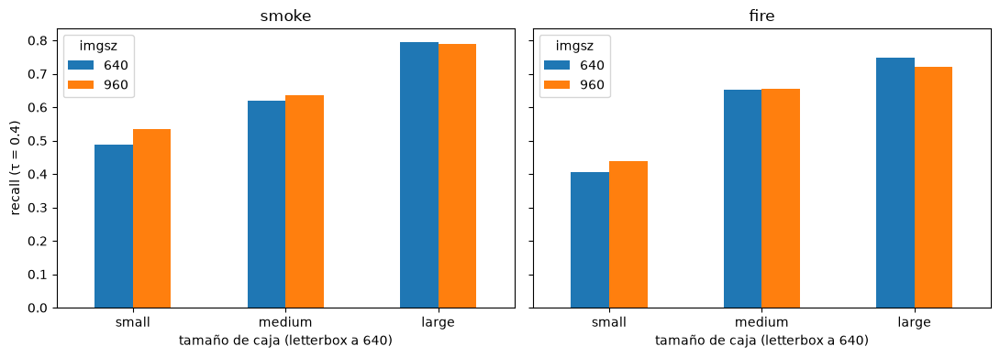

In [8]:
gts_tam = gts.assign(tamano=evaluacion.tamano(gts, 640))
filas = []
for run, imgsz in RUNS_H1.items():
    if not (RUNS_DIR / run / "weights" / "best.pt").exists() and not SMOKE_TEST:
        print(f"[!] Falta {run}: se saltea")
        continue
    p_run, _ = predecir(run, test_imgs, CACHE_DIR / f"test_preds_{run}.csv", con_gt=True)
    _, g = evaluacion.emparejar(evaluacion.filtrar(p_run, TAU), gts_tam)
    r = g.groupby(["clase", "tamano"], observed=True)["detectada"].agg(["mean", "size"]).reset_index()
    filas.append(r.assign(run=run, imgsz=imgsz))

if filas:
    h1 = pd.concat(filas).rename(columns={"mean": "recall", "size": "n_cajas"})
    tabla = h1.pivot_table(index=["clase", "tamano"], columns="imgsz", values="recall", observed=True).round(3)
    tabla["n_cajas"] = h1.groupby(["clase", "tamano"], observed=True)["n_cajas"].first()
    display(tabla)

    fig, axes = plt.subplots(1, len(CLASES), figsize=(11, 4), sharey=True)
    for ax, clase in zip(axes, CLASES):
        t = h1[h1["clase"] == clase].pivot_table(index="tamano", columns="imgsz", values="recall", observed=True)
        t.plot.bar(ax=ax, rot=0)
        ax.set_title(clase)
        ax.set_xlabel("tamaño de caja (letterbox a 640)")
        ax.set_ylabel(f"recall (τ = {TAU})")
        ax.legend(title="imgsz")
    fig.tight_layout()
    for ext in ("png", "pdf"):
        fig.savefig(FIG_DIR / f"h1_recall_por_tamano.{ext}", dpi=150, bbox_inches="tight")

## 6. H2: ¿sirven las imágenes negativas?

R1 y R5 solo difieren en que R5 no vio las 6.458 imágenes negativas de train; val y test son los mismos. H2 dice que entrenar con ellas **baja los falsos positivos sin perder recall**. Se mide a varios τ, porque un modelo puede parecer mejor a un umbral y peor a otro:

- falsos positivos por imagen negativa del test (las 2.005 sin fuego ni humo),
- % de imágenes negativas con al menos un falso positivo,
- recall por clase.

Una curva por run: recall vs. falsos positivos por imagen negativa al variar τ. Si H2 se cumple, la de R1 queda arriba a la izquierda de la de R5.

yolo11n_640_noneg_s42 en test_preds_yolo11n_640_noneg_s42:   0%|          | 0/4306 [00:00<?, ?it/s]

,FP_por_img_neg,pct_img_neg_con_FP,P_smoke,R_smoke,P_fire,R_fire
run,,,,,,
con negativas (R1),0.007,0.648,0.846,0.717,0.779,0.554
sin negativas (R5),0.329,28.778,0.663,0.737,0.744,0.548


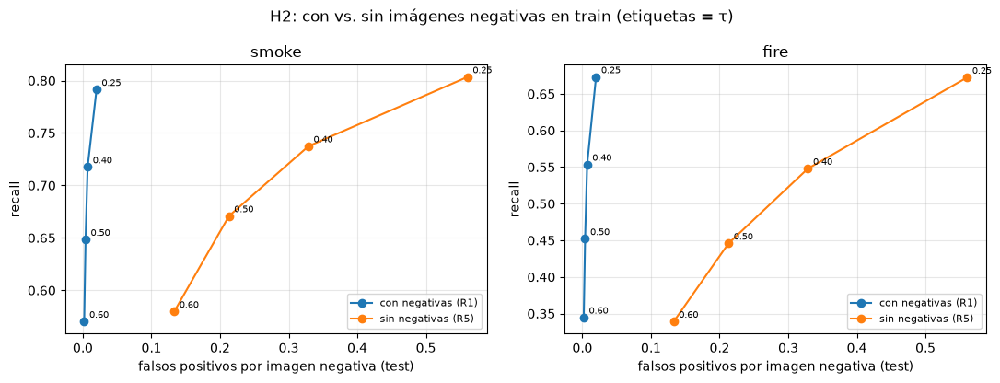

In [9]:
TAUS_H2 = [0.25, 0.40, 0.50, 0.60]
filas = []
for run, etiqueta in RUNS_H2.items():
    if not (RUNS_DIR / run / "weights" / "best.pt").exists() and not SMOKE_TEST:
        print(f"[!] Falta {run}: se saltea")
        continue
    p_run, _ = predecir(run, test_imgs, CACHE_DIR / f"test_preds_{run}.csv", con_gt=True)
    filas += [{"run": etiqueta, **evaluacion.evaluar(p_run, gts, negativas, tau)} for tau in TAUS_H2]

if filas:
    h2 = pd.DataFrame(filas)
    h2.to_csv(RESULTS_DIR / "h2_negativas.csv", index=False)
    cols = ["FP_por_img_neg", "pct_img_neg_con_FP", "P_smoke", "R_smoke", "P_fire", "R_fire"]
    display(h2[h2["tau"] == TAU].set_index("run")[cols].round(3))

    fig, axes = plt.subplots(1, len(CLASES), figsize=(11, 4.2), sharex=True)
    for ax, clase in zip(axes, CLASES):
        for run, g in h2.groupby("run"):
            ax.plot(g["FP_por_img_neg"], g[f"R_{clase}"], "o-", label=run)
            for r in g.itertuples():
                ax.annotate(f"{r.tau:.2f}", (r.FP_por_img_neg, getattr(r, f"R_{clase}")), textcoords="offset points", xytext=(4, 3), fontsize=7)
        ax.set_title(clase)
        ax.set_xlabel("falsos positivos por imagen negativa (test)")
        ax.set_ylabel("recall")
        ax.grid(alpha=0.3)
        ax.legend(fontsize=8)
    fig.suptitle("H2: con vs. sin imágenes negativas en train (etiquetas = τ)")
    fig.tight_layout()
    for ext in ("png", "pdf"):
        fig.savefig(FIG_DIR / f"h2_negativas.{ext}", dpi=150, bbox_inches="tight")

## 7. Set de estrés

~150 imágenes **sin** fuego ni humo, externas a D-Fire, en `data/estres/<categoria>/` (`nubes`, `niebla`, `atardecer_sol`, `luces_nocturnas`, `vapor_chimeneas`, `reflejos`). Fuente sugerida: HPWREN / AI For Mankind. No llevan cajas: cualquier detección sobre τ es un falso positivo.

Métricas por categoría, para R1 (con y sin clasificador) y R5 (H2 fuera de D-Fire): falsos positivos por imagen y % de imágenes con al menos un falso positivo.

In [10]:
CATEGORIAS = ["nubes", "niebla", "atardecer_sol", "luces_nocturnas", "vapor_chimeneas", "reflejos"]
for c in CATEGORIAS:
    (ESTRES_DIR / c).mkdir(parents=True, exist_ok=True)
estres = [(c.name, p) for c in sorted(ESTRES_DIR.iterdir()) if c.is_dir()
          for p in sorted(c.iterdir()) if p.suffix.lower() in {".jpg", ".jpeg", ".png", ".webp"}]
print(f"Set de estrés: {len(estres)} imágenes en {ESTRES_DIR}")

if estres:
    cat = {p.stem: c for c, p in estres}
    RUTA.update({p.stem: p for _, p in estres})
    n_img = pd.Series(cat).value_counts().rename("imagenes")
    variantes = {}
    for run in dict.fromkeys([RUN, *RUNS_H2]):
        if not (RUNS_DIR / run / "weights" / "best.pt").exists() and not SMOKE_TEST:
            continue
        p_est, _ = predecir(run, [p for _, p in estres], CACHE_DIR / f"estres_preds_{run}.csv", con_gt=False)
        p_est["categoria"] = p_est["imagen"].map(cat)
        variantes[run] = evaluacion.filtrar(p_est, TAU)
        if run == RUN and clasificador is not None:
            variantes[f"{run} + clasificador"] = evaluacion.filtrar(p_est, TAU, UMBRAL_CLF)

    filas = []
    for nombre, p in variantes.items():
        g = p.groupby("categoria")
        t = pd.DataFrame({"fp_por_imagen": g.size(), "imgs_con_fp": g["imagen"].nunique()}).reindex(n_img.index, fill_value=0)
        t["fp_por_imagen"] = t["fp_por_imagen"] / n_img
        t["pct_imgs_con_fp"] = 100 * t.pop("imgs_con_fp") / n_img
        filas.append(t.assign(variante=nombre, imagenes=n_img))
    tabla_estres = pd.concat(filas).reset_index(names="categoria")
    tabla_estres.to_csv(RESULTS_DIR / "estres.csv", index=False)
    display(tabla_estres.pivot_table(index="categoria", columns="variante", values=["fp_por_imagen", "pct_imgs_con_fp"]).round(2))

    fig, ax = plt.subplots(figsize=(9, 4))
    tabla_estres.pivot_table(index="categoria", columns="variante", values="pct_imgs_con_fp").plot.bar(ax=ax, rot=20)
    ax.set_ylabel(f"% imágenes con falso positivo (τ = {TAU})")
    ax.set_title("Set de estrés")
    fig.tight_layout()
    for ext in ("png", "pdf"):
        fig.savefig(FIG_DIR / f"estres.{ext}", dpi=150, bbox_inches="tight")
else:
    print("Cargar las imágenes en las subcarpetas de", ESTRES_DIR)

Set de estrés: 0 imágenes en c:\Proyectos\CV2\detección_incendios\data\estres
Cargar las imágenes en las subcarpetas de c:\Proyectos\CV2\detección_incendios\data\estres


In [11]:
# Falsos positivos de mayor confianza por categoría del set de estrés
if estres and RUN in variantes and len(variantes[RUN]):
    top = variantes[RUN].sort_values("conf", ascending=False).groupby("categoria").head(3)
    top = top.assign(tipo="FP", en_negativa=True, confusion_clase=False)
    mostrar(top, f"Set de estrés: falsos positivos de mayor confianza ({RUN})", f"estres_peores_{RUN}", columnas=6)